# 01 — Data quality and coverage

This notebook establishes the reliable analytical sample before modeling.

**Unit of observation**

- Daily data: `date × permno`
- Intraday data: `date × permno × checkpoint`

**Target rule**

- A target is observed only when `target_found = TRUE` and `auction_volume` is non-null.
- Missing auction records are not converted to zero.
- Dates explicitly marked `exclude_from_model` are ineligible.
- Intraday checkpoints after an early close are not treated as missing data failures.

In [1]:
from pathlib import Path
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (11, 5.5), "figure.dpi": 120})

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "blackrock_data").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate blackrock_data. Run the notebook inside the Capstone project.")

DATA = PROJECT_ROOT / "blackrock_data"
OUTPUT = PROJECT_ROOT / "outputs" / "eda"
con = duckdb.connect()

AUCTION = str(DATA / "stock_daily/auction_daily/year=*/auction_daily_*.parquet")
CRSP = str(DATA / "stock_daily/crsp_daily/year=*/crsp_daily_*.parquet")
TRADE = str(DATA / "stock_intraday/trade_checkpoints/year=*/trade_checkpoints_*.parquet")
EVENTS = str(DATA / "events/event_calendar.parquet")
INDUSTRY = str(DATA / "reference/industry_history.parquet")
ANOMALIES = str(DATA / "quality/auction_source_anomalies.parquet")

def sql(query, params=None):
    return con.execute(query, params or []).df()

print(f"Project root: {PROJECT_ROOT}")

OUT = OUTPUT / "01_data_quality"
OUT.mkdir(parents=True, exist_ok=True)

Matplotlib is building the font cache; this may take a moment.


Project root: /Users/aramesh/Documents/Fall 2026/Capstone


## Dataset inventory

In [2]:
inventory = sql(f"""
WITH crsp AS (
  SELECT count(*) AS rows, count(DISTINCT date) AS dates,
         count(DISTINCT permno) AS permnos, min(date) AS min_date, max(date) AS max_date
  FROM read_parquet('{CRSP}', union_by_name=true, hive_partitioning=true)
), auction AS (
  SELECT count(*) AS rows, count(DISTINCT date) AS dates,
         count(DISTINCT permno) AS permnos, min(date) AS min_date, max(date) AS max_date
  FROM read_parquet('{AUCTION}', union_by_name=true, hive_partitioning=true)
), trades AS (
  SELECT count(*) AS rows, count(DISTINCT date) AS dates,
         count(DISTINCT permno) AS permnos, min(date) AS min_date, max(date) AS max_date
  FROM read_parquet('{TRADE}', union_by_name=true, hive_partitioning=true)
), market AS (
  SELECT count(*) AS rows, count(DISTINCT date) AS dates,
         NULL::BIGINT AS permnos, min(date) AS min_date, max(date) AS max_date
  FROM read_parquet('{str(DATA / "market/market_daily.parquet")}')
), sector AS (
  SELECT count(*) AS rows, count(DISTINCT date) AS dates,
         NULL::BIGINT AS permnos, min(date) AS min_date, max(date) AS max_date
  FROM read_parquet('{str(DATA / "sector/sector_daily.parquet")}')
)
SELECT 'CRSP daily' AS dataset, * FROM crsp
UNION ALL SELECT 'Auction daily', * FROM auction
UNION ALL SELECT 'Trade checkpoints', * FROM trades
UNION ALL SELECT 'Market daily', * FROM market
UNION ALL SELECT 'Sector daily', * FROM sector
""")
display(inventory)
inventory.to_csv(OUT / "dataset_inventory.csv", index=False)

,dataset,rows,dates,permnos,min_date,max_date
0,CRSP daily,4927078,3772,2414,2011-01-03,2025-12-31
1,Auction daily,3594398,2766,2149,2015-01-02,2025-12-31
2,Trade checkpoints,17971990,2766,2149,2015-01-02,2025-12-31
3,Market daily,3772,3772,<NA>,2011-01-03,2025-12-31
4,Sector daily,45264,3772,<NA>,2011-01-03,2025-12-31


## Annual target coverage

,year,stock_days,auction_rows,observed_targets,missing_targets,target_coverage,trading_days,securities
0,2015,341909,341903,337566,4343,0.9873,252,1426
1,2016,329950,329950,325638,4312,0.9869,252,1386
2,2017,321370,321370,318040,3330,0.9896,251,1348
3,2018,317656,317656,313807,3849,0.9879,251,1329
4,2019,316550,316550,308724,7826,0.9753,252,1316
5,2020,312434,312434,303168,9266,0.9703,253,1320
6,2021,336769,336769,321564,15205,0.9549,252,1477
7,2022,353277,353277,328634,24643,0.9302,251,1469
8,2023,331648,331648,318679,12969,0.9609,250,1397
9,2024,321631,321631,316212,5419,0.9832,252,1333


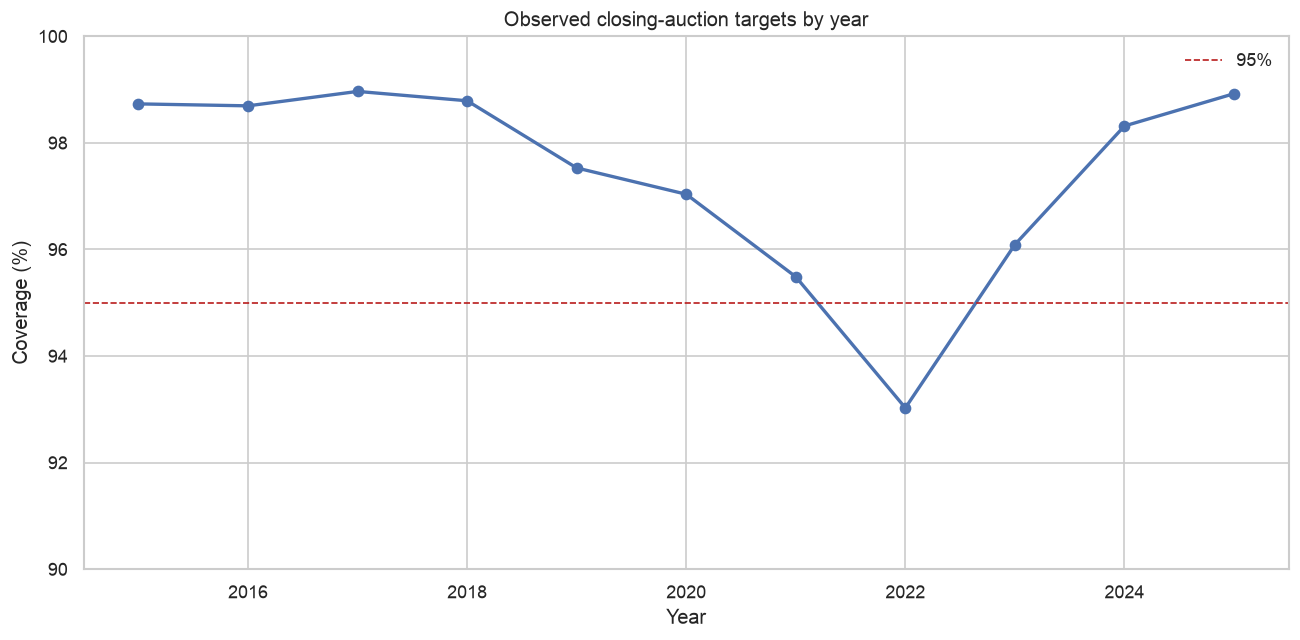

In [3]:
annual = sql(f"""
WITH c AS (
  SELECT date, permno
  FROM read_parquet('{CRSP}', union_by_name=true, hive_partitioning=true)
  WHERE date >= DATE '2015-01-01'
), a AS (
  SELECT date, permno, auction_volume, auction_price, target_found
  FROM read_parquet('{AUCTION}', union_by_name=true, hive_partitioning=true)
)
SELECT year(c.date) AS year,
       count(*) AS stock_days,
       count(a.permno) AS auction_rows,
       count(a.auction_volume) AS observed_targets,
       count(*) - count(a.auction_volume) AS missing_targets,
       count(a.auction_volume)::DOUBLE / count(*) AS target_coverage,
       count(DISTINCT c.date) AS trading_days,
       count(DISTINCT c.permno) AS securities
FROM c LEFT JOIN a USING (date, permno)
GROUP BY 1 ORDER BY 1
""")
display(annual)
annual.to_csv(OUT / "annual_target_coverage.csv", index=False)

fig, ax = plt.subplots()
ax.plot(annual["year"], 100 * annual["target_coverage"], marker="o", linewidth=2)
ax.axhline(95, color="#b91c1c", linestyle="--", linewidth=1, label="95%")
ax.set(title="Observed closing-auction targets by year", ylabel="Coverage (%)", xlabel="Year", ylim=(90, 100))
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "annual_target_coverage.png", bbox_inches="tight")
plt.show()

## Daily coverage and source anomalies

,date,stocks,observed,coverage,exclude_from_model,reason
1159,2019-08-12,1261,484,0.3838,True,Abnormally incomplete NYSE condition-6 auction...
1834,2022-04-14,1418,1295,0.9133,False,NaN
1849,2022-05-06,1417,1296,0.9146,False,NaN
1858,2022-05-19,1417,1298,0.9160,False,NaN
1868,2022-06-03,1417,1298,0.9160,False,NaN
1843,2022-04-28,1416,1298,0.9167,False,NaN
1850,2022-05-09,1417,1299,0.9167,False,NaN
1820,2022-03-25,1416,1299,0.9174,False,NaN
1866,2022-06-01,1417,1300,0.9174,False,NaN
1841,2022-04-26,1416,1300,0.9181,False,NaN


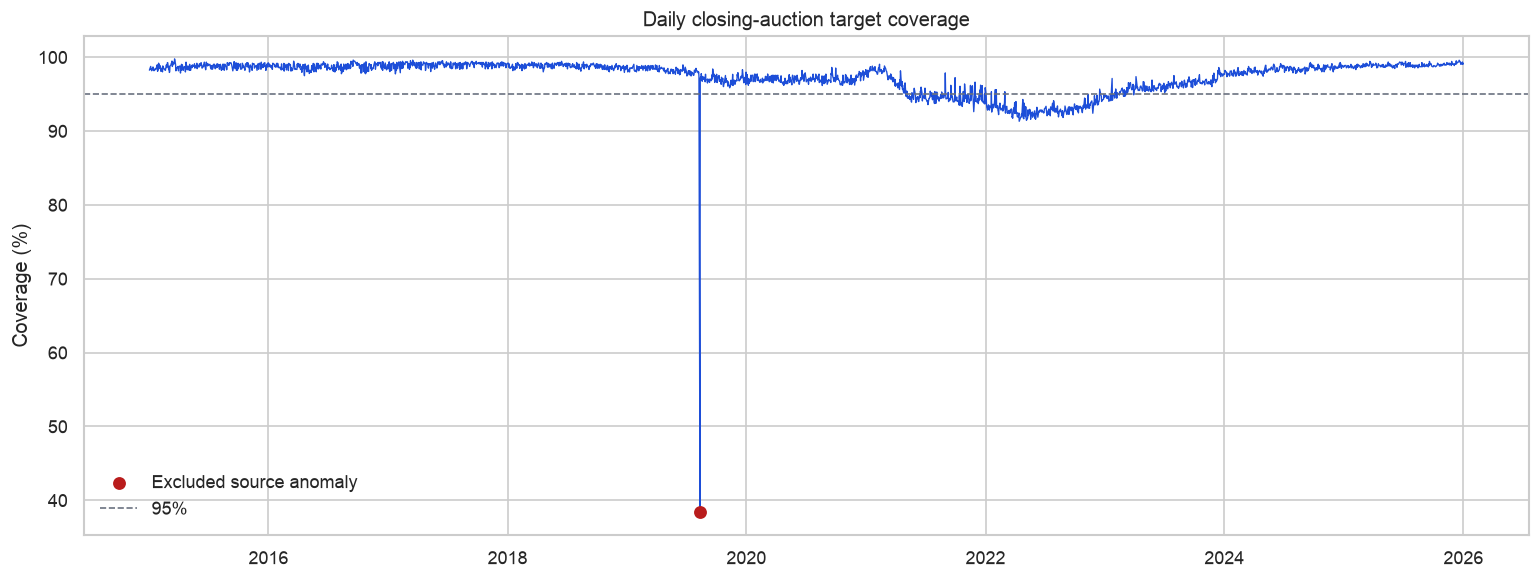

In [4]:
daily = sql(f"""
WITH c AS (
  SELECT date, permno
  FROM read_parquet('{CRSP}', union_by_name=true, hive_partitioning=true)
  WHERE date >= DATE '2015-01-01'
), a AS (
  SELECT date, permno, auction_volume
  FROM read_parquet('{AUCTION}', union_by_name=true, hive_partitioning=true)
), an AS (
  SELECT date, exclude_from_model, reason
  FROM read_parquet('{ANOMALIES}')
)
SELECT c.date, count(*) AS stocks, count(a.auction_volume) AS observed,
       count(a.auction_volume)::DOUBLE / count(*) AS coverage,
       coalesce(bool_or(an.exclude_from_model), false) AS exclude_from_model,
       any_value(an.reason) AS reason
FROM c LEFT JOIN a USING (date, permno)
LEFT JOIN an USING (date)
GROUP BY c.date ORDER BY c.date
""")
display(daily.nsmallest(12, "coverage"))
daily.to_csv(OUT / "daily_target_coverage.csv", index=False)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(daily["date"], 100 * daily["coverage"], color="#1d4ed8", linewidth=0.8)
flagged = daily[daily["exclude_from_model"]]
ax.scatter(flagged["date"], 100 * flagged["coverage"], color="#b91c1c", s=45, zorder=4, label="Excluded source anomaly")
ax.axhline(95, color="#6b7280", linestyle="--", linewidth=1, label="95%")
ax.set(title="Daily closing-auction target coverage", ylabel="Coverage (%)", xlabel="")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "daily_target_coverage.png", bbox_inches="tight")
plt.show()

## Integrity checks

In [5]:
checks = sql(f"""
WITH a AS (
  SELECT * FROM read_parquet('{AUCTION}', union_by_name=true, hive_partitioning=true)
), c AS (
  SELECT * FROM read_parquet('{CRSP}', union_by_name=true, hive_partitioning=true)
), t AS (
  SELECT * FROM read_parquet('{TRADE}', union_by_name=true, hive_partitioning=true)
)
SELECT 'auction duplicate date-permno groups' AS check_name,
       (SELECT count(*) FROM (SELECT date, permno FROM a GROUP BY 1,2 HAVING count(*) > 1)) AS issue_count
UNION ALL SELECT 'CRSP duplicate date-permno groups',
       (SELECT count(*) FROM (SELECT date, permno FROM c GROUP BY 1,2 HAVING count(*) > 1))
UNION ALL SELECT 'trade duplicate date-permno-checkpoint groups',
       (SELECT count(*) FROM (SELECT date, permno, checkpoint FROM t GROUP BY 1,2,3 HAVING count(*) > 1))
UNION ALL SELECT 'negative auction volumes', (SELECT count(*) FROM a WHERE auction_volume < 0)
UNION ALL SELECT 'nonpositive observed auction prices', (SELECT count(*) FROM a WHERE auction_volume IS NOT NULL AND auction_price <= 0)
UNION ALL SELECT 'auction share above 100%', (SELECT count(*) FROM a WHERE auction_share_daily_volume > 1)
UNION ALL SELECT 'target flag/value disagreements',
       (SELECT count(*) FROM a WHERE coalesce(target_found, false) <> (auction_volume IS NOT NULL))
""")
display(checks)
checks.to_csv(OUT / "integrity_checks.csv", index=False)

,check_name,issue_count
0,auction duplicate date-permno groups,0
1,CRSP duplicate date-permno groups,0
2,trade duplicate date-permno-checkpoint groups,0
3,negative auction volumes,0
4,nonpositive observed auction prices,0
5,auction share above 100%,0
6,target flag/value disagreements,0


## Missing targets by market-cap decile

,size_decile,stock_days,observed_targets,target_coverage
0,1,360734,310083,0.8596
1,2,360450,331436,0.9195
2,3,360141,353754,0.9823
3,4,359873,355981,0.9892
4,5,359593,357871,0.9952
5,6,359262,358157,0.9969
6,7,359008,357899,0.9969
7,8,358744,358555,0.9995
8,9,358431,358348,0.9998
9,10,358168,357801,0.9990


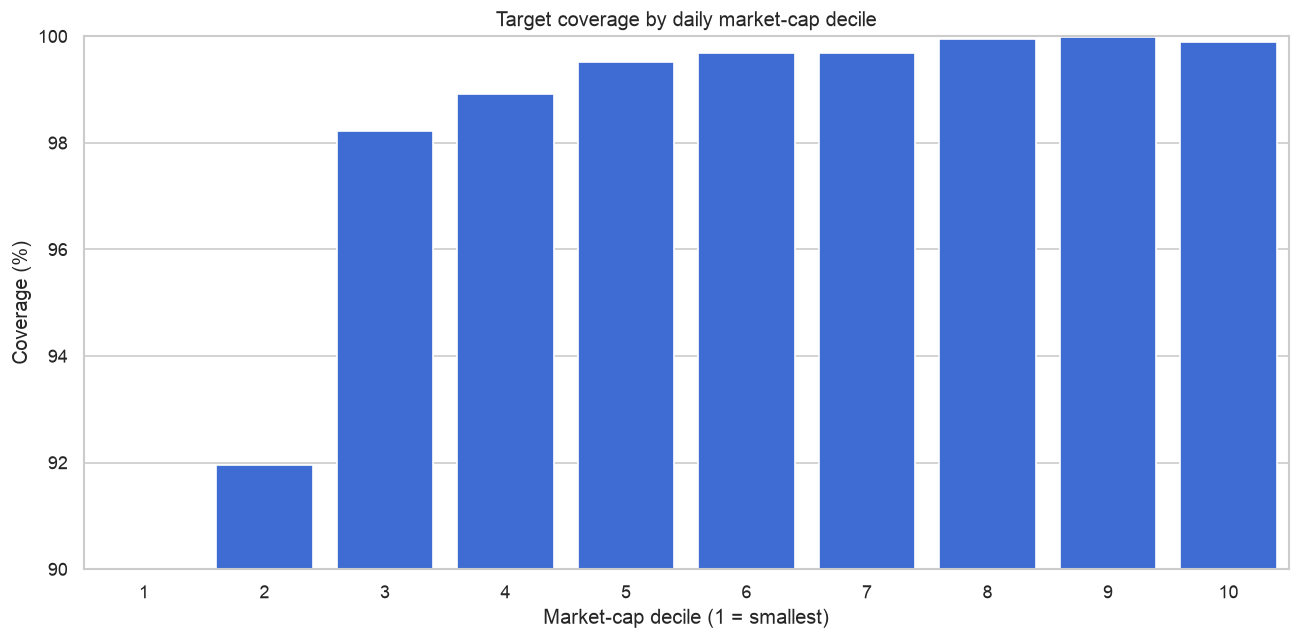

In [6]:
size_coverage = sql(f"""
WITH c AS (
  SELECT date, permno, market_cap_usd,
         ntile(10) OVER (PARTITION BY date ORDER BY market_cap_usd) AS size_decile
  FROM read_parquet('{CRSP}', union_by_name=true, hive_partitioning=true)
  WHERE date >= DATE '2015-01-01'
), a AS (
  SELECT date, permno, auction_volume
  FROM read_parquet('{AUCTION}', union_by_name=true, hive_partitioning=true)
)
SELECT size_decile, count(*) AS stock_days, count(a.auction_volume) AS observed_targets,
       count(a.auction_volume)::DOUBLE / count(*) AS target_coverage
FROM c LEFT JOIN a USING (date, permno)
GROUP BY 1 ORDER BY 1
""")
display(size_coverage)
size_coverage.to_csv(OUT / "target_coverage_by_size_decile.csv", index=False)

fig, ax = plt.subplots()
sns.barplot(data=size_coverage, x="size_decile", y=size_coverage["target_coverage"] * 100, color="#2563eb", ax=ax)
ax.set(title="Target coverage by daily market-cap decile", xlabel="Market-cap decile (1 = smallest)", ylabel="Coverage (%)", ylim=(90, 100))
fig.tight_layout()
fig.savefig(OUT / "target_coverage_by_size_decile.png", bbox_inches="tight")
plt.show()

## Intraday checkpoint coverage

,checkpoint,rows,data_found_rate,after_close_rows,missing_cum_volume,missing_vwap
0,10:30,3594398,0.9967,0,11990,37422
1,12:00,3594398,0.9967,0,11990,22615
2,14:00,3594398,0.9885,29540,41432,44999
3,15:00,3594398,0.9885,29540,41432,42592
4,15:30,3594398,0.9885,29540,41432,41432


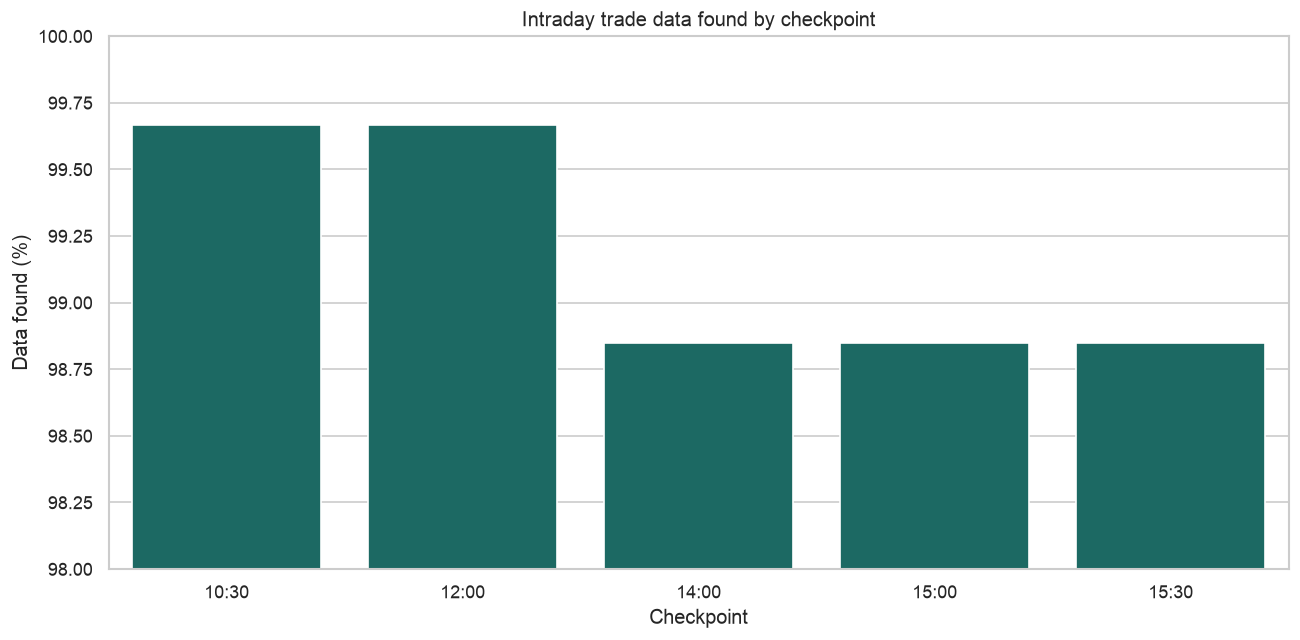

In [7]:
checkpoint = sql(f"""
SELECT checkpoint, count(*) AS rows,
       avg(checkpoint_data_found::INTEGER) AS data_found_rate,
       count(*) FILTER (WHERE checkpoint_after_market_close) AS after_close_rows,
       count(*) FILTER (WHERE cum_volume IS NULL) AS missing_cum_volume,
       count(*) FILTER (WHERE vwap IS NULL) AS missing_vwap
FROM read_parquet('{TRADE}', union_by_name=true, hive_partitioning=true)
GROUP BY 1 ORDER BY strptime(checkpoint, '%H:%M')
""")
display(checkpoint)
checkpoint.to_csv(OUT / "intraday_checkpoint_coverage.csv", index=False)

fig, ax = plt.subplots()
sns.barplot(data=checkpoint, x="checkpoint", y=checkpoint["data_found_rate"] * 100, color="#0f766e", ax=ax)
ax.set(title="Intraday trade data found by checkpoint", xlabel="Checkpoint", ylabel="Data found (%)", ylim=(98, 100))
fig.tight_layout()
fig.savefig(OUT / "intraday_checkpoint_coverage.png", bbox_inches="tight")
plt.show()

## Auction schema drift

In [8]:
files = sorted((DATA / "stock_daily/auction_daily").glob("year=*/*.parquet"))
schemas = {}
for file in files:
    year = int(file.parent.name.split("=")[1])
    schemas[year] = [r[0] for r in con.execute(f"DESCRIBE SELECT * FROM read_parquet('{file}')").fetchall()]

all_columns = sorted(set().union(*map(set, schemas.values())))
schema_matrix = pd.DataFrame({year: [col in columns for col in all_columns] for year, columns in schemas.items()}, index=all_columns)
schema_summary = pd.DataFrame({
    "year": sorted(schemas),
    "column_count": [len(schemas[y]) for y in sorted(schemas)],
    "schema_family": ["TAQ-oriented" if len(schemas[y]) < 40 else "CRSP-enriched" for y in sorted(schemas)],
})
display(schema_summary)
display(schema_matrix.loc[schema_matrix.nunique(axis=1) > 1].astype(int))
schema_summary.to_csv(OUT / "auction_schema_summary.csv", index=False)
schema_matrix.astype(int).to_csv(OUT / "auction_schema_matrix.csv")

,year,column_count,schema_family
0,2015,34,TAQ-oriented
1,2016,32,TAQ-oriented
2,2017,32,TAQ-oriented
3,2018,32,TAQ-oriented
4,2019,34,TAQ-oriented
5,2020,58,CRSP-enriched
6,2021,58,CRSP-enriched
7,2022,58,CRSP-enriched
8,2023,58,CRSP-enriched
9,2024,32,TAQ-oriented


,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
ask,0,0,0,0,0,1,1,1,1,0,1
auction_close_abs_diff,0,0,0,0,0,1,1,1,1,0,1
auction_close_diff_bps,0,0,0,0,0,1,1,1,1,0,1
auction_gt_positive_crsp_volume,0,0,0,0,0,1,1,1,1,0,1
auction_price_raw,1,1,1,1,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...
tr_seqnum,1,1,1,1,1,0,0,0,0,1,0
trading_status,0,0,0,0,0,1,1,1,1,0,1
tradingsymbol,1,1,1,1,1,0,0,0,0,1,0
us_incorporated,0,0,0,0,0,1,1,1,1,0,1


## Modeling sample definition

In [9]:
splits = sql(f"""
WITH c AS (
  SELECT date, permno
  FROM read_parquet('{CRSP}', union_by_name=true, hive_partitioning=true)
  WHERE date >= DATE '2015-01-01'
), a AS (
  SELECT date, permno, auction_volume, target_found
  FROM read_parquet('{AUCTION}', union_by_name=true, hive_partitioning=true)
), an AS (
  SELECT date, exclude_from_model FROM read_parquet('{ANOMALIES}')
)
SELECT CASE WHEN c.date <= DATE '2021-12-31' THEN 'Train: 2015–2021'
            WHEN c.date <= DATE '2023-12-31' THEN 'Validation: 2022–2023'
            ELSE 'Test: 2024–2025' END AS sample,
       count(*) AS stock_days,
       count(a.auction_volume) AS observed_targets,
       count(*) FILTER (WHERE a.target_found AND a.auction_volume IS NOT NULL
                         AND NOT coalesce(an.exclude_from_model, false)) AS eligible_targets,
       count(*) FILTER (WHERE a.target_found AND a.auction_volume IS NOT NULL
                         AND NOT coalesce(an.exclude_from_model, false))::DOUBLE / count(*) AS eligible_rate
FROM c LEFT JOIN a USING (date, permno)
LEFT JOIN an USING (date)
GROUP BY 1 ORDER BY min(c.date)
""")
display(splits)
splits.to_csv(OUT / "modeling_sample_by_split.csv", index=False)

,sample,stock_days,observed_targets,eligible_targets,eligible_rate
0,Train: 2015–2021,2276638,2228507,2228023,0.9786
1,Validation: 2022–2023,684925,647313,647313,0.9451
2,Test: 2024–2025,632841,624065,624065,0.9861


## Decisions from this notebook

1. Use 2015–2025 for target modeling; retain 2011–2014 only as daily-history context.
2. Exclude documented source-anomaly dates, currently 2019-08-12.
3. Keep missing targets as missing, never as zero.
4. Use `date × permno` and `date × permno × checkpoint` as required unique keys.
5. Mask checkpoint observations marked after the market close.
6. Build a canonical auction staging view before feature engineering because the yearly raw schemas differ.
7. Report results by year and size group because target coverage is not constant over time or across the cross-section.